## Import Library

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_regression

## Load dataset

In [2]:
windowed_df = pd.read_csv('cleaned_hourly_demand.csv')

In [3]:
windowed_df.head()

,restaurant_id,order_timestamp,demand,service_process_mean,order_hour,day_of_week,is_weekend,weather,traffic_level,total_items,avg_subtotal
0,RES_0001,2025-10-01 00:00:00,6,15.500000,0,Wednesday,0,Cloudy,Low,18,27.715000
1,RES_0001,2025-10-01 01:00:00,3,11.666667,1,Wednesday,0,Cloudy,Low,9,29.683333
2,RES_0001,2025-10-01 02:00:00,1,19.000000,2,Wednesday,0,Cloudy,Low,6,52.030000
3,RES_0001,2025-10-01 03:00:00,1,5.000000,3,Wednesday,0,Cloudy,Low,1,9.710000
4,RES_0001,2025-10-01 04:00:00,2,12.000000,4,Wednesday,0,Cloudy,Low,4,16.650000


## EDA

### Distribution of Orders by Hour 

<Axes: title={'center': 'Distribution of Orders by Hour'}, xlabel='order_hour'>

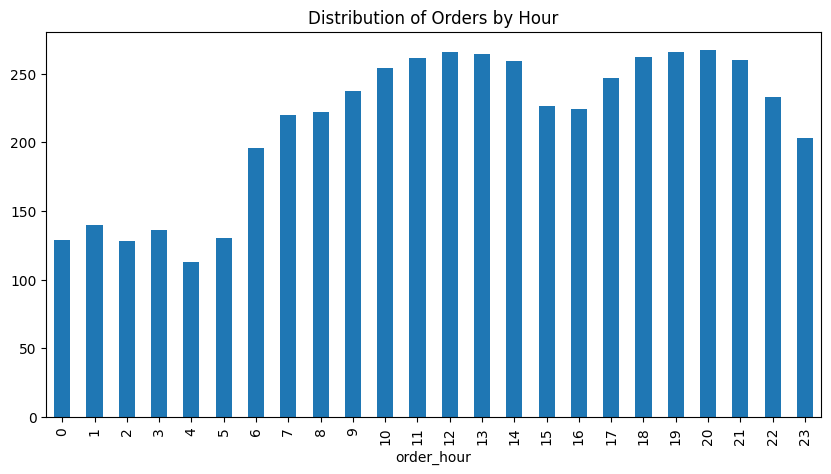

In [4]:
windowed_df['order_hour'].value_counts().sort_index().plot(kind='bar', figsize=(10, 5), title='Distribution of Orders by Hour')

### Distribution of Orders by Traffic Level

<Axes: title={'center': 'Distribution of Orders by Traffic Level'}, xlabel='traffic_level'>

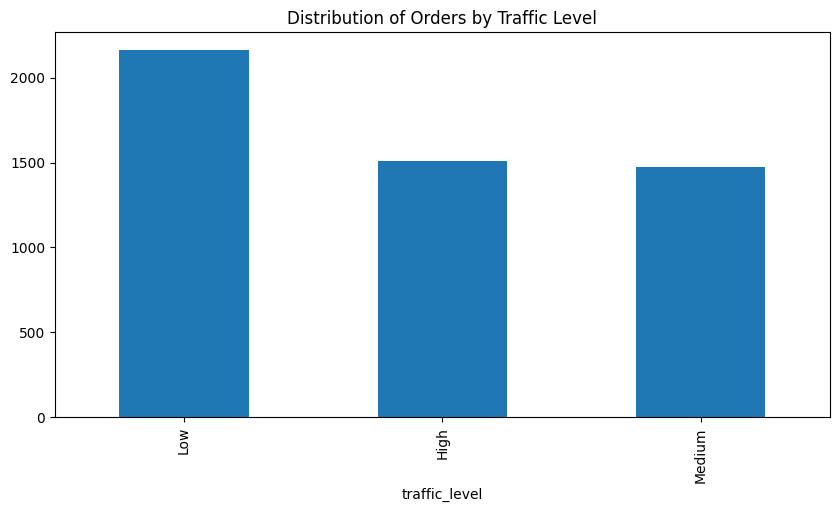

In [5]:
windowed_df['traffic_level'].value_counts().plot(kind='bar', figsize=(10, 5), title='Distribution of Orders by Traffic Level')

### Distribution of Service Process Time

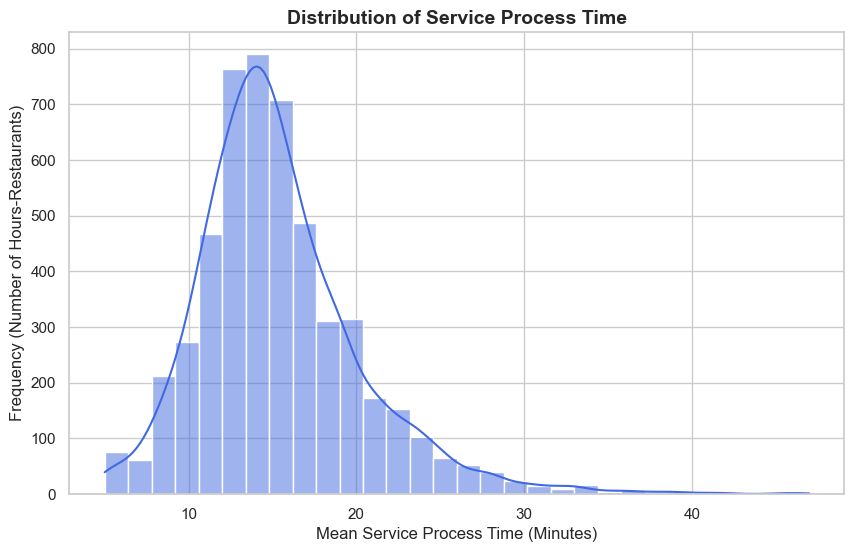

In [6]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.histplot(
    data=windowed_df, 
    x='service_process_mean', 
    kde=True, 
    color='royalblue', 
    bins=30
)

plt.title('Distribution of Service Process Time', fontsize=14, fontweight='bold')
plt.xlabel('Mean Service Process Time (Minutes)', fontsize=12)
plt.ylabel('Frequency (Number of Hours-Restaurants)', fontsize=12)

plt.show()

## Correlation features

### Heatmap Correlation numeric features

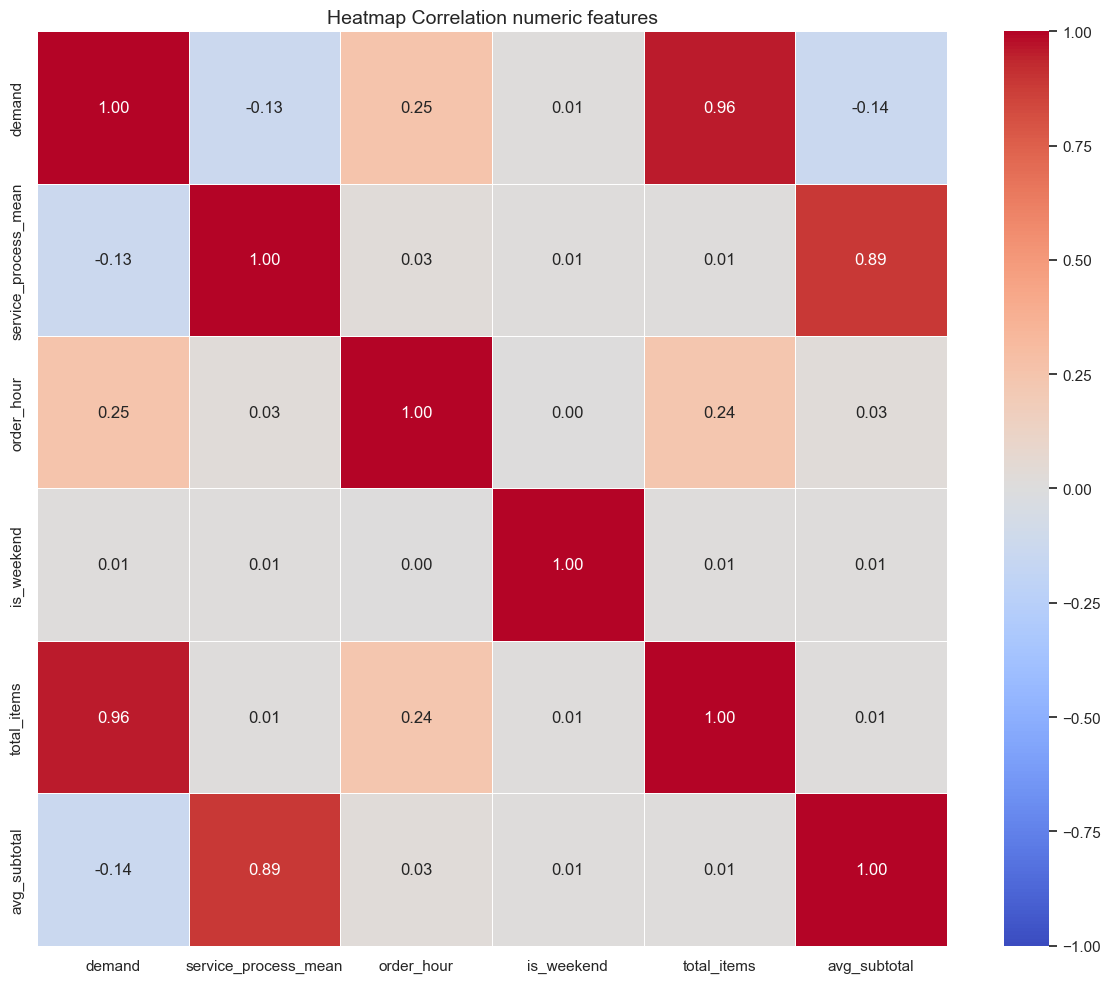

In [7]:
numeric_df = windowed_df.select_dtypes(include=["number"])

full_corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    full_corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Heatmap Correlation numeric features", fontsize=14)
plt.tight_layout()
plt.show()

### Mutual Information Scores for Categorical Features

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13184\3456925213.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


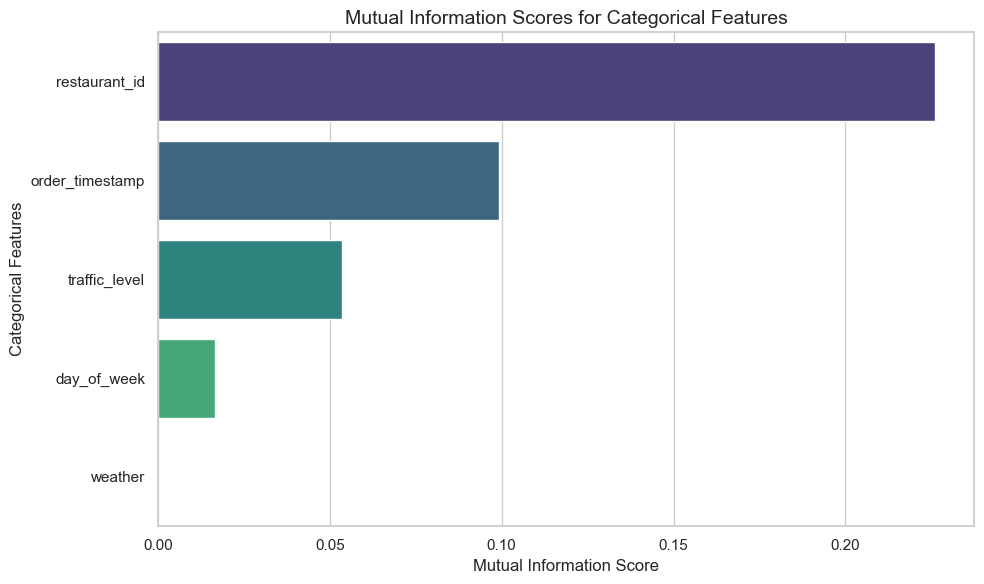

['restaurant_id', 'order_timestamp', 'day_of_week', 'weather', 'traffic_level']
restaurant_id      0.226166
order_timestamp    0.099215
traffic_level      0.053594
day_of_week        0.016468
weather            0.000000
dtype: float64


In [8]:
X_cat = windowed_df.select_dtypes(include=["object", "category"])

y = windowed_df["demand"]

encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X_cat)
X_encoded_df = pd.DataFrame(X_encoded, columns=X_cat.columns)

mi_scores = mutual_info_regression(X_encoded_df, y, random_state=42)

mi_scores_series = pd.Series(mi_scores, index=X_cat.columns).sort_values(
    ascending=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=mi_scores_series.values, y=mi_scores_series.index, palette="viridis"
)

plt.title(
    "Mutual Information Scores for Categorical Features",
    fontsize=14,
)
plt.xlabel("Mutual Information Score")
plt.ylabel("Categorical Features")
plt.tight_layout()
plt.show()

print(list(X_cat.columns))
print(mi_scores_series)